In [70]:
# ДЗ 7
# Преоразовать существующий код для распознавания последовательности рукописных символов в текст.
# Написать генератор произвольной последовательности рукописных символов.

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ
# Сгенерировать набор текстовых строк из допустимых символов.
# Каждому набору поставить в соотвествие массив изоражений соответствующих символов.
# Добавить пробелы для разделения слов, символы пробелов не использовать во время классификации.

# КЛАССИФИКАЦИЯ (k ближайших соседей) (пример AIM practice 2)
# Часть символов оставить для обучения классификатора . Остальные  классифицировать
# по аналогии с примером mnist с прошлого занятия. Т.е. преобразовывать изображение в вектор.
# Выбрать оптимальный классификатор в зависимости от k- количество соседей.
# Метрика для измерения точности классификации, и выбора оптимального классификатора относительно параметра k - accuracy.

# РАСПОЗНАВАНИЕ
# заменить inf_net на последовательное применение следующих шагов:
# 1. генерация изображения с последовательностью символов
# 2. Выделение объектов оставляете как есть.
# 3. Примернить k-nn для решения задачи классификации. 
# 4. Вывести результат

In [71]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
rng = np.random.default_rng(123)

## Загрузка набора рукописных цифр

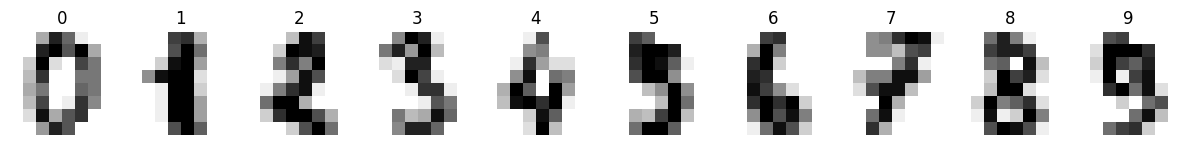

In [72]:
digits = datasets.load_digits()

images = digits.images
labels = digits.target

fig, axes = plt.subplots(1, 10, figsize=(12, 2))

for digit, ax in enumerate(axes):
    index = np.where(labels == digit)[0][0]

    ax.imshow(images[index], cmap='gray_r')
    ax.set_title(str(digit))
    ax.axis('off')

plt.tight_layout()
plt.show()

In [73]:
indices = np.arange(len(images))
idx_train, idx_other = train_test_split(indices, test_size=0.4, random_state=42, stratify=labels)
idx_val, idx_test = train_test_split(idx_other, test_size=0.5, random_state=42, stratify=labels[idx_other])

## Подготовка изображений для классификации

In [74]:
SCALE = 8
IMAGE_SIZE = 32

def to_image(image8):
    ink = (np.clip(image8, 0, 16) * 255 / 16).astype(np.uint8)
    gray = 255 - cv2.resize(ink, (8 * SCALE, 8 * SCALE), interpolation=cv2.INTER_NEAREST)
    return gray


def tight_crop(gray):
    _, mask = cv2.threshold(gray, 210, 255, cv2.THRESH_BINARY_INV)
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return gray
    return gray[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


def to_vector(gray):
    cropped = tight_crop(gray)
    ink = 255 - cropped
    h, w = ink.shape
    scale = min(28 / w, 28 / h)
    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))
    
    interpolation = (cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    small = cv2.resize(ink, (new_w, new_h), interpolation=interpolation)
    canvas = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)

    x0 = (IMAGE_SIZE - new_w) // 2
    y0 = (IMAGE_SIZE - new_h) // 2
    canvas[y0:y0 + new_h, x0:x0 + new_w] = small
    return (canvas.astype(np.float32) / 255).ravel()

X = np.stack([to_vector(to_image(image)) for image in images])
y = labels

## Классификация методом k ближайших соседей

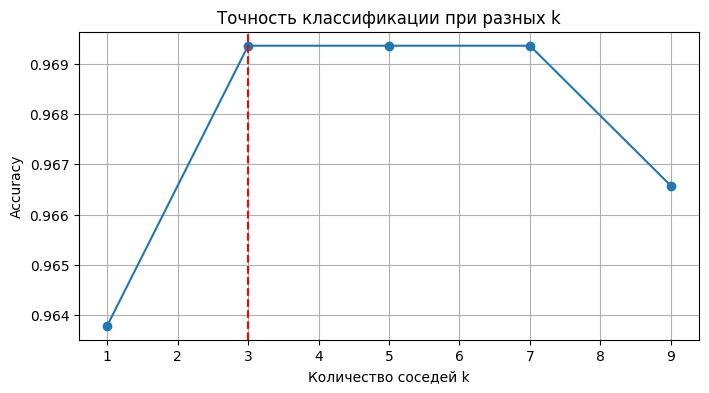

In [75]:
k_values = [1, 3, 5, 7, 9]
accuracy_values = []
for k in k_values:
    classifier = KNeighborsClassifier(n_neighbors=k)
    classifier.fit(X[idx_train], y[idx_train])
    predicted = classifier.predict(X[idx_val])
    acc = accuracy_score(y[idx_val], predicted)
    accuracy_values.append(acc)

best_k = k_values[np.argmax(accuracy_values)]
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X[idx_train], y[idx_train])

test_predictions = best_knn.predict(X[idx_test])
test_accuracy = accuracy_score(y[idx_test], test_predictions)
matrix = confusion_matrix(y[idx_test], test_predictions)

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracy_values, marker='o')
plt.axvline(best_k, color='red', linestyle='--')
plt.xlabel('Количество соседей k')
plt.ylabel('Accuracy')
plt.title('Точность классификации при разных k')
plt.grid(True)
plt.show()

In [76]:
best_k, round(test_accuracy, 4)

(3, 0.9778)

In [77]:
matrix

array([[34,  0,  0,  0,  1,  0,  0,  0,  0,  0],
       [ 0, 37,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  1, 34,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 37,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0, 36,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 36,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  0,  0, 35,  0,  1,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 36,  0,  0],
       [ 0,  3,  0,  0,  0,  0,  1,  0, 31,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0, 36]])

## Генерация последовательностей рукописных символов

In [78]:
test_by_digit = {digit: idx_test[y[idx_test] == digit] for digit in range(10)}

def generate_sequence(n_words=3, min_len=2, max_len=4):
    words = []
    for _ in range(n_words):
        length = int(rng.integers(min_len, max_len + 1))
        word = ''.join(str(digit) for digit in rng.integers(0, 10, size=length))
        words.append(word)

    text = ' '.join(words)
    char_images = []
    for ch in text:
        if ch == ' ':
            char_images.append(None)
        else:
            candidates = test_by_digit[int(ch)]
            index = int(rng.choice(candidates))

            char_images.append(to_image(images[index]))

    return text, char_images

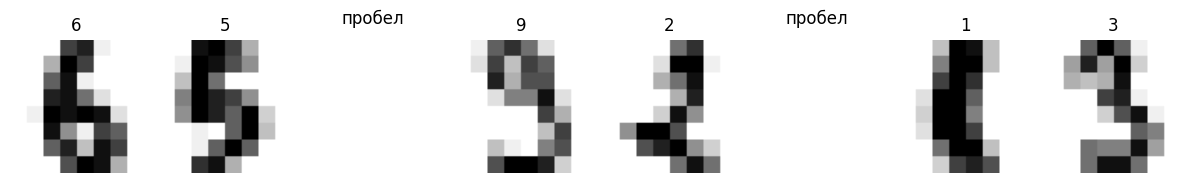

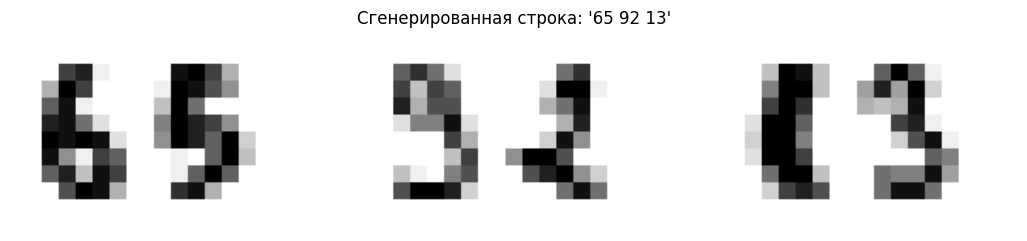

In [79]:
def render_sequence(text, char_images, char_gap=13, word_gap=52):
    height = 94
    x = 15
    crops = []

    for ch, img in zip(text, char_images):
        if ch == ' ':
            x += word_gap
            continue

        part = tight_crop(img)
        h, w = part.shape
        y0 = height - 15 - h
        crops.append((part, x, y0))
        x += w + char_gap

    canvas = np.full((height, x + 15), 255, dtype=np.uint8)

    for part, x0, y0 in crops:
        h, w = part.shape
        canvas[y0:y0 + h, x0:x0 + w] = part

    return canvas

generated_dataset = [generate_sequence() for _ in range(10)]
true_text, char_images = generated_dataset[0]
sequence = render_sequence(true_text, char_images)
fig, axes = plt.subplots(1, len(char_images), figsize=(max(12, len(char_images)), 2))
for ax, ch, img in zip(axes, true_text, char_images):
    if img is not None:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)

    ax.set_title('пробел' if ch == ' ' else ch)
    ax.axis('off')

plt.tight_layout()
plt.show()
plt.figure(figsize=(13, 3))
plt.imshow(sequence, cmap='gray', vmin=0, vmax=255)
plt.title(f"Сгенерированная строка: '{true_text}'")
plt.axis('off')
plt.show()

## Выделение объектов и распознавание последовательности

In [80]:
def recognize_sequence(image):
    _, mask = cv2.threshold(image, 210, 255, cv2.THRESH_BINARY_INV)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for cnt in contours:
        x, y0, w, h = cv2.boundingRect(cnt)
        if w * h > 25:
            boxes.append((x, y0, w, h))

    boxes.sort(key=lambda box: box[0])
    result = []
    previous_end = None
    annotated = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    for x, y0, w, h in boxes:
        if previous_end is not None:
            gap = x - previous_end

            if gap > 32:
                result.append(' ')

        crop = image[y0:y0 + h, x:x + w]
        features = to_vector(crop).reshape(1, -1)
        predicted_digit = best_knn.predict(features)[0]
        result.append(str(predicted_digit))
        cv2.rectangle(annotated, (x, y0), (x + w, y0 + h), (255, 0, 0), 2)
        cv2.putText(annotated, str(predicted_digit), (x, max(12, y0 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 125, 0), 1)
        previous_end = x + w

    return ''.join(result), annotated, boxes

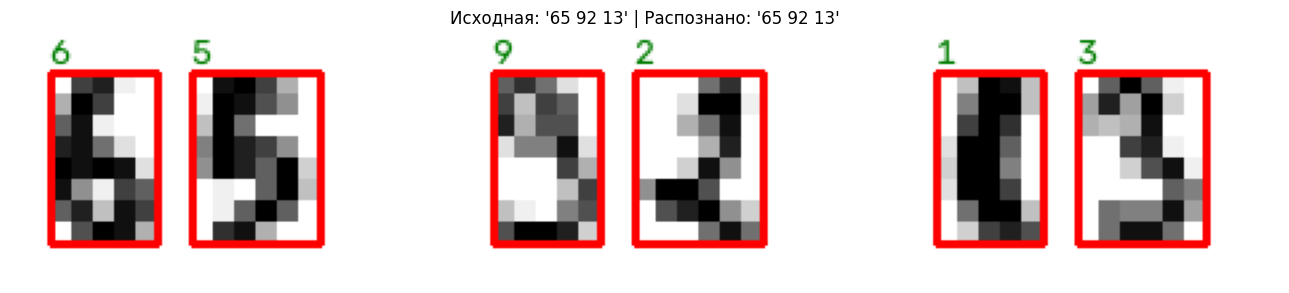

In [81]:
predicted_text, annotated, boxes = recognize_sequence(sequence)
plt.figure(figsize=(13, 3))
plt.imshow(annotated)
plt.title(f"Исходная: '{true_text}' | " f"Распознано: '{predicted_text}'")
plt.axis('off')
plt.tight_layout()
plt.show()

## Проверка распознавания нескольких последовательностей

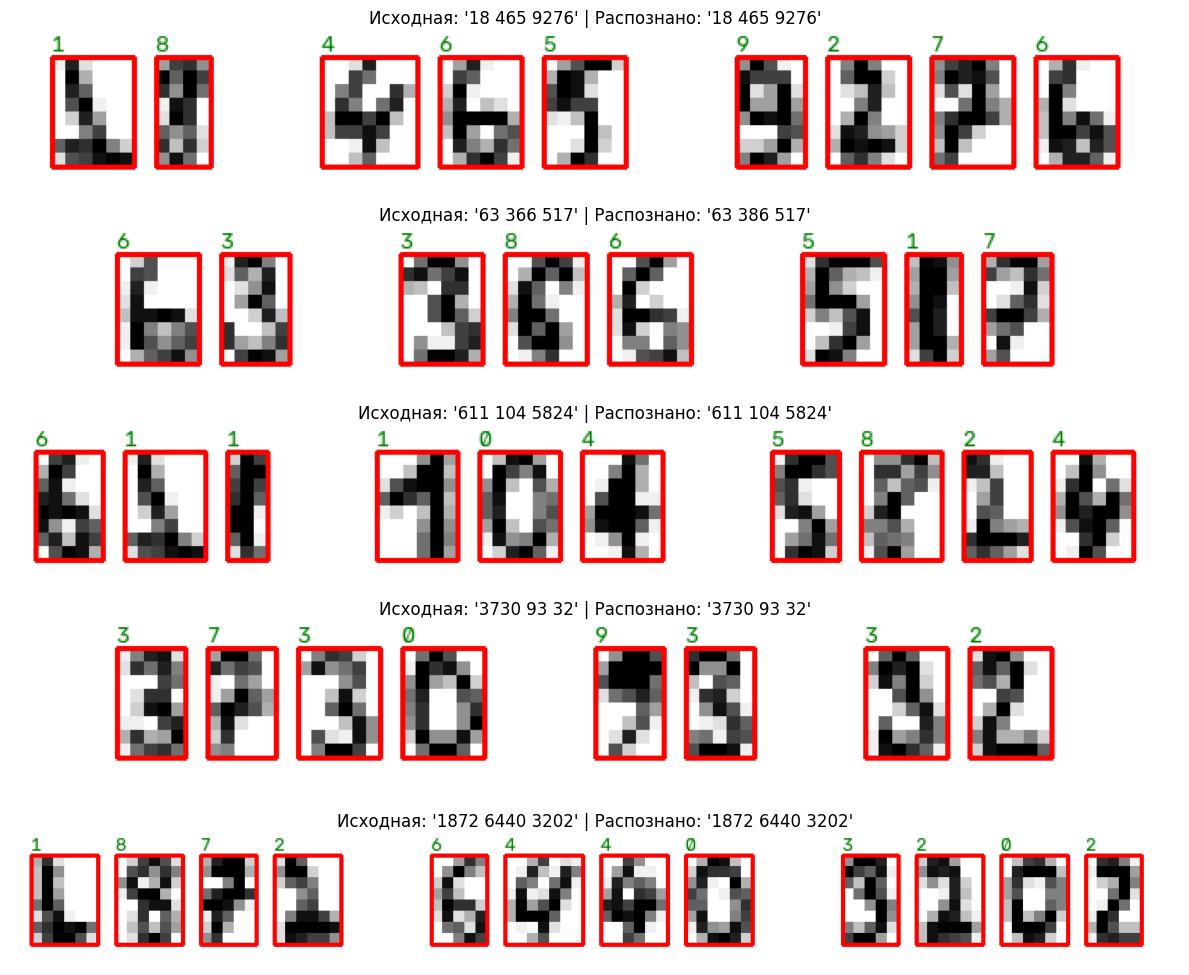

(4, 5)

In [82]:
n_checks = 5
correct_lines = 0
fig, axes = plt.subplots(n_checks, 1, figsize=(12, 2 * n_checks))

for i in range(n_checks):
    text, imgs = generate_sequence()
    test_sequence = render_sequence(text, imgs)
    predicted, annotated, boxes = recognize_sequence(test_sequence)
    if text == predicted:
        correct_lines += 1

    axes[i].imshow(annotated)
    axes[i].set_title(f"Исходная: '{text}' | Распознано: '{predicted}'")
    axes[i].axis('off')

plt.tight_layout()
plt.show()
correct_lines, n_checks
